# Inspecting waveforms

First produce some waveform with `./build/icxe-daq run --config config/default.json --max-events 10`

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from read_waveforms import plot_waveform

In [24]:
# find waveform file
import glob

#files = glob.glob('../data/PMT_1_0kV_2vpp*/wf_*.bin', recursive=True)
#files = glob.glob('../data/PMT_1_0kV_0-5vpp*/wf_*.bin', recursive=True)
#files = sorted(glob.glob('../data/PMT_1_1kV_2vpp_15adccounts_20261026T1809*/wf_*.bin', recursive=True))
#files = sorted(glob.glob('../data/PMT_1_2kV_2vpp_15adccounts_20261026T195*/wf_*.bin', recursive=True))
files = sorted(glob.glob('../data/full_scale_test*/wf_*.bin', recursive=True))
print(len(files))
for path in files:
    print(path)

1
../data/full_scale_test_20261029T152037Z/wf_00000.bin


In [25]:
from read_waveforms import load_waveforms

loaded = [load_waveforms(path) for path in sorted(files)]
waveforms = np.concatenate([w for w, _ in loaded], axis=0)
headers = {
    key: np.concatenate([h[key] for _, h in loaded])
    for key in loaded[0][1]
}

In [26]:
waveforms.shape

(10, 2, 1020)

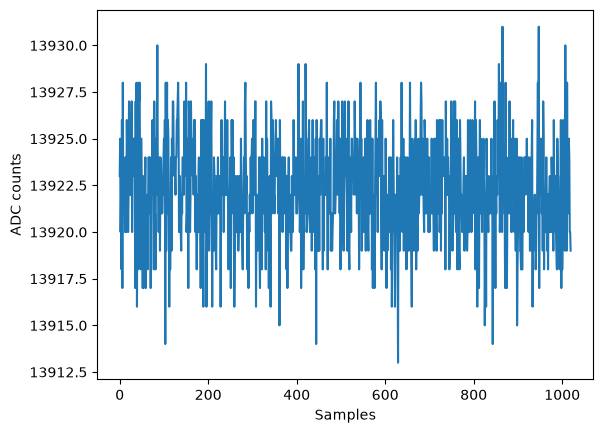

In [27]:
plot_waveform(waveforms[0,0,:], full_range=False)

In [28]:
np.std(waveforms[0,0,:]) * 2 / 2**14 * 1000

np.float64(0.33716146945886527)

In [29]:
164 * 0.5 / 2**14 * 1000

5.0048828125

In [505]:
wfs = waveforms[:,0,:]

In [506]:
wfs.shape

(1100000, 1020)

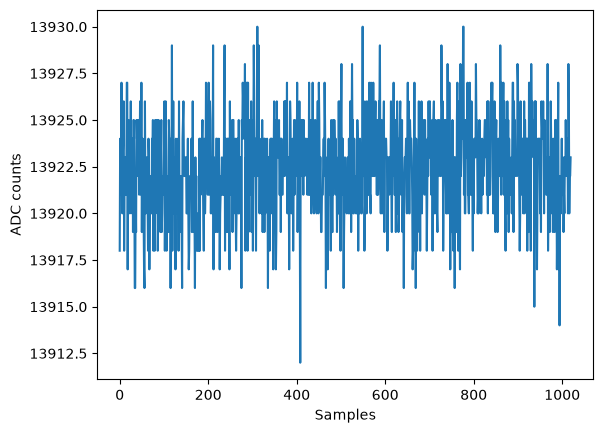

In [507]:
plot_waveform(wfs[1,:])

In [508]:
baselines = np.mean(wfs[:,:200], axis = 1)


In [ ]:
#baselines_1_2kv_low_light_10adccounts = copy.deepcopy(baselines)

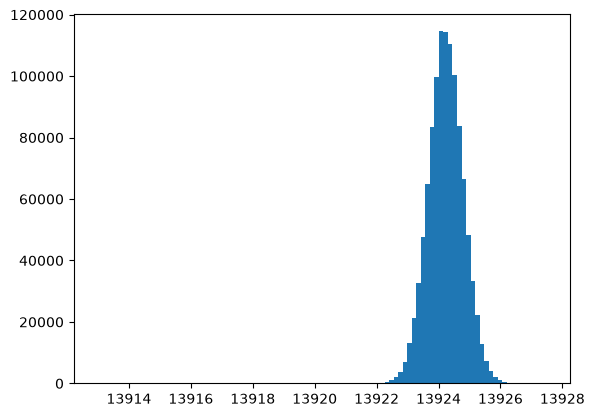

13924.236582918184 0.5593519755501439


In [510]:
plt.hist(baselines, bins = 100)
plt.show()
print(np.mean(baselines), np.std(baselines))

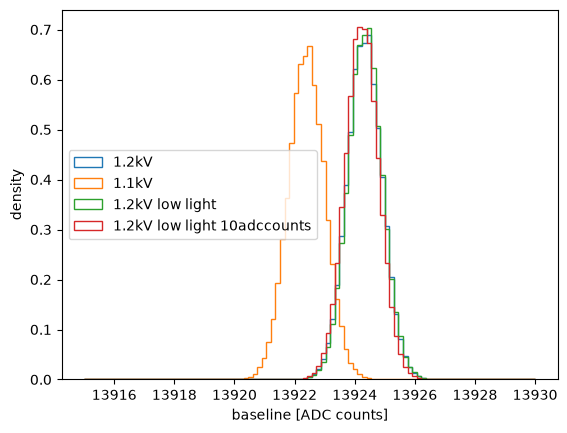

In [606]:
plt.hist(baselines_1_2kv, bins = np.linspace(13915, 13930, 100), histtype='step', label='1.2kV', density=True)
plt.hist(baselines_1_1kv, bins = np.linspace(13915, 13930, 100), histtype='step', label='1.1kV', density=True)
plt.hist(baselines_1_2kv_low_light, bins = np.linspace(13915, 13930, 100), histtype='step', label='1.2kV low light', density=True)
plt.hist(baselines_1_2kv_low_light_10adccounts, bins = np.linspace(13915, 13930, 100), histtype='step', label='1.2kV low light 10adccounts', density=True)

plt.ylabel('density')
plt.xlabel('baseline [ADC counts]')
plt.legend()
plt.show()



In [512]:
amplitudes = -(np.min(wfs[:,:], axis = 1) - baselines)

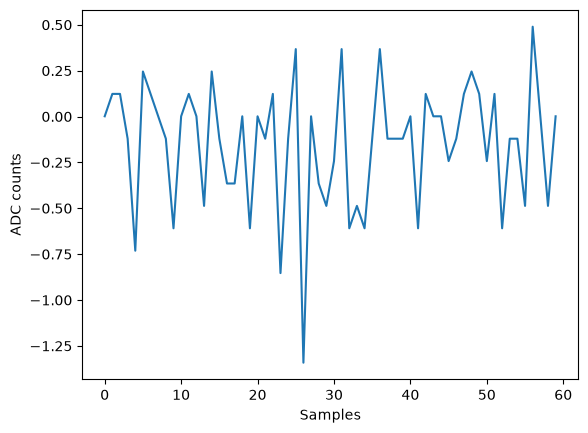

In [513]:
plot_waveform(wfs[1000,380:440]-baselines[1000], yscale='mV', dynamic_range=2)

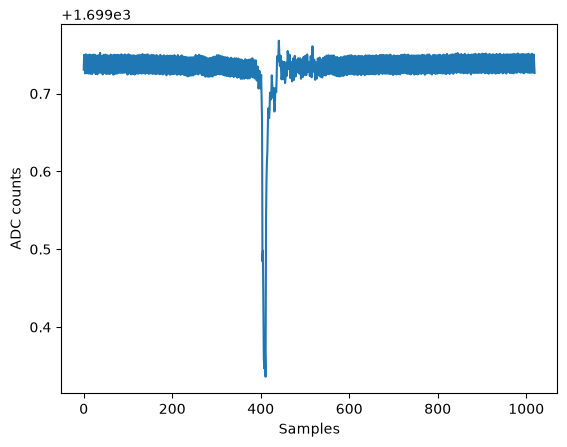

In [514]:
plot_waveform(np.mean(wfs[:,:], axis =0), yscale='mV', dynamic_range=2)

### Amplitude spectra and dissection

In [592]:
amplitudes_mv = amplitudes* 2 / 2**14 * 1000

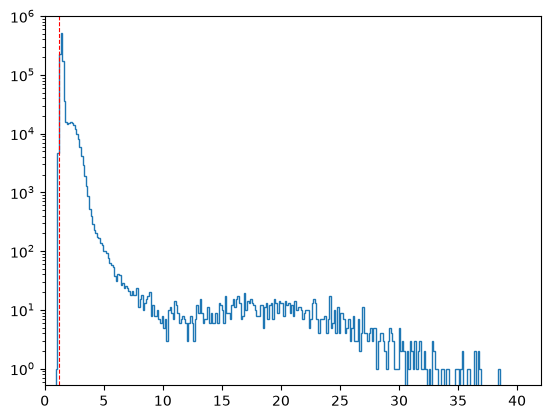

In [593]:
plt.hist(amplitudes_mv, bins = np.linspace(0, 40, 300), histtype='step')
plt.axvline(10*2/2**14*1000, color='red', label = 'threshold', lw = 0.8, ls = '--')
#plt.axvline(1.8, color='green')
#plt.grid()
plt.yscale('log')
plt.xlim(0, None)
plt.show()


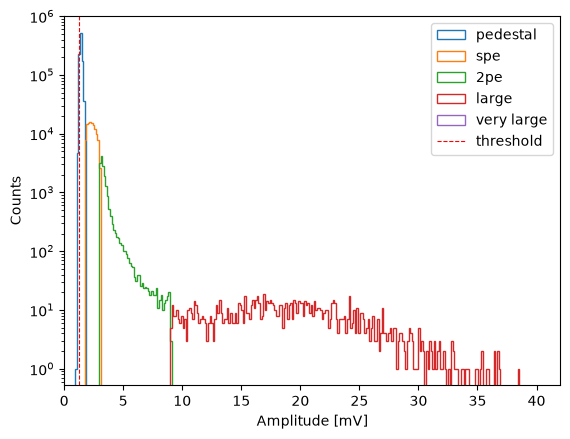

In [618]:
amplitudes_pedestal = amplitudes_mv[(amplitudes_mv <= 1.8)]
amplitudes_spe = amplitudes_mv[np.where((amplitudes_mv > 1.8) & (amplitudes_mv < 3))]
amplitudes_2pe = amplitudes_mv[np.where((amplitudes_mv > 3) & (amplitudes_mv < 9))]
amplitudes_large = amplitudes_mv[np.where((amplitudes_mv > 9)& (amplitudes_mv < 40))]
amplitudes_verylarge = amplitudes_mv[np.where((amplitudes_mv > 40))]

plt.hist(amplitudes_pedestal, bins = np.linspace(0, 40, 300), histtype='step', label = 'pedestal')
plt.hist(amplitudes_spe, bins = np.linspace(0, 40, 300), histtype='step', label = 'spe')
plt.hist(amplitudes_2pe, bins = np.linspace(0, 40, 300), histtype='step', label = '2pe')
plt.hist(amplitudes_large, bins = np.linspace(0, 40, 300), histtype='step', label = 'large')
plt.hist(amplitudes_verylarge, bins = np.linspace(0, 40, 300), histtype='step', label = 'very large')

plt.axvline(10*2/2**14*1000, color='red', label = 'threshold', lw = 0.8, ls = '--')
#plt.axvline(1.8, color='green')
#plt.grid()
plt.yscale('log')
plt.xlim(0, None)
plt.legend()
plt.xlabel('Amplitude [mV]')
plt.ylabel('Counts')
plt.show()


In [625]:
from spe_fit_funcs import plot_region_waveforms

ImportError: cannot import name 'plot_region_waveforms' from 'spe_fit_funcs' (/home/xenon/icdaq/ICXe-DAQ/tools/spe_fit_funcs.py)

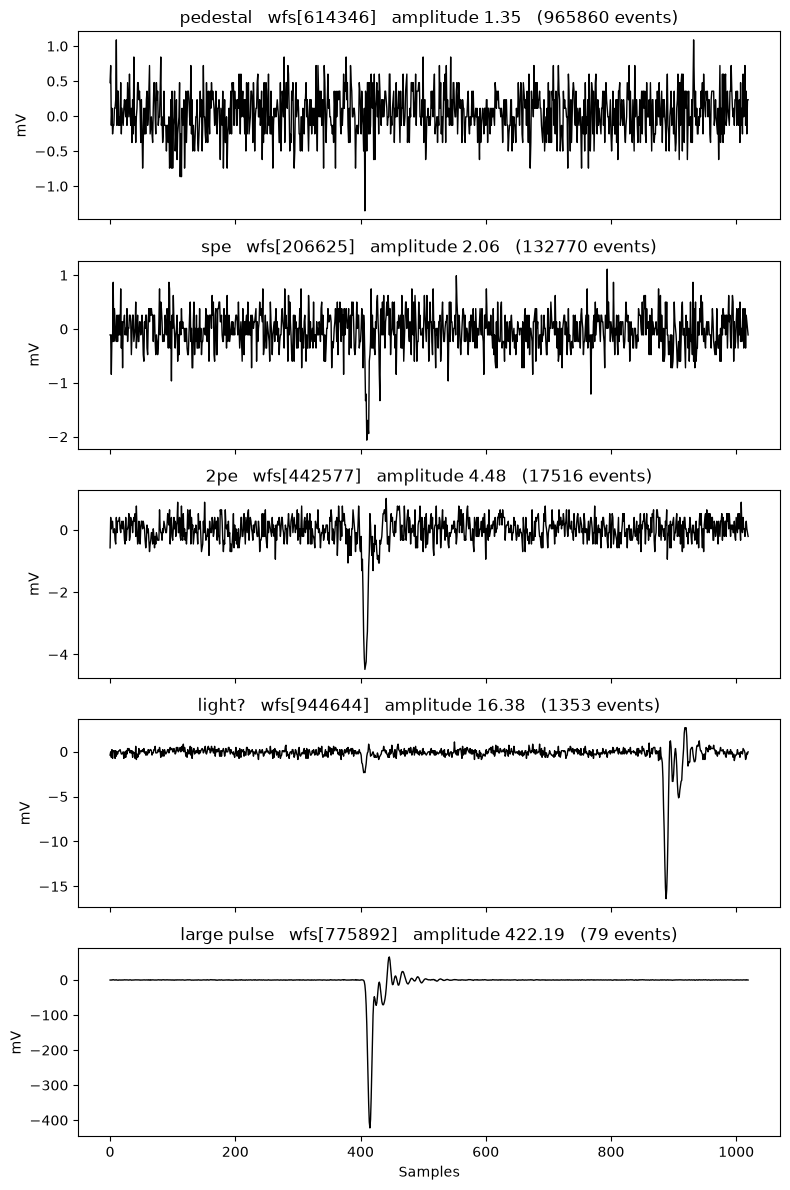

In [626]:
chosen, fig, axes = plot_region_waveforms(
    {
        "pedestal": amplitudes_pedestal,
        "spe": amplitudes_spe,
        "2pe": amplitudes_2pe,
        "light?": amplitudes_large,
        "large pulse": amplitudes_verylarge
    },
    amplitudes_mv,
    wfs,
    baselines=baselines,
    which="random",
)

### Fit SPE

In [628]:
from spe_fit_funcs import fit_spe
amplitudes_spe = amplitudes_mv[np.where((amplitudes_mv > 1.8) & (amplitudes_mv < 10))]

mu = 2.195 ± 0.004
2*mu = 4.389, 3*mu = 6.584
sigma/mu = 0.269 ± 0.002
sigmas = 0.590, 1.180, 1.771
amplitudes = 6958.0 ± 22.8, 58.9 ± 1.8, 9.4 ± 0.6
chi2_red = 25.976 (3402.9 / 131)


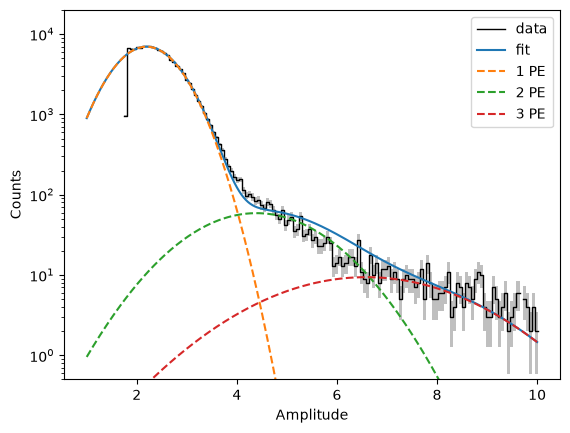

In [631]:
fit_values, fig, ax = fit_spe(
    amplitudes_spe, 
    n_gaussians=3, 
    linear=False, 
    plot=True, 
    print_fit=True,
    fit_range=(1.0, 10.0),
    bins=None,
    mu_bounds=(1.8, 4.0))

mu = 2.196 ± 0.004
2*mu = 4.391
sigma/mu = 0.268 ± 0.002
sigmas = 0.588, 1.176
amplitudes = 6958.2 ± 22.9, 58.6 ± 2.8
slope = -0.34 ± 0.45, intercept = 8.6 ± 3.9
chi2_red = 25.548 (3321.3 / 130)


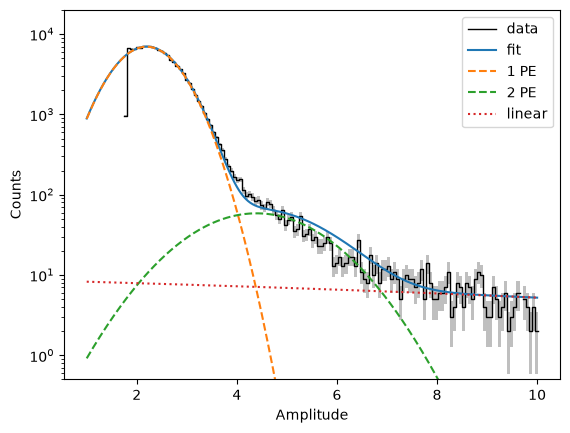

In [632]:
fit_values, fig, ax = fit_spe(
    amplitudes_spe, 
    n_gaussians=2, 
    linear=True, 
    plot=True, 
    print_fit=True,
    fit_range=(1.0, 10.0),
    bins=None,
    mu_bounds=(1.8, 4.0))

mu = 2.196 ± 0.004
2*mu = 4.391, 3*mu = 6.587
sigma/mu = 0.268 ± 0.002
sigmas = 0.588, 1.176, 1.764
amplitudes = 6958.2 ± 28.4, 58.6 ± 11.9, 0.0 ± 8.6
slope = -0.34 ± 2.92, intercept = 8.6 ± 29.8
chi2_red = 25.746 (3321.3 / 129)


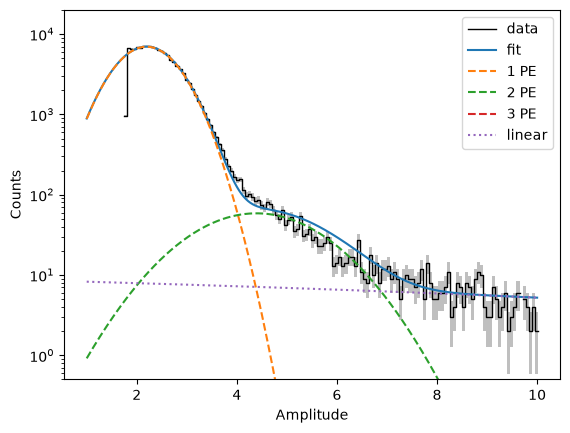

In [635]:
fit_values, fig, ax = fit_spe(
    amplitudes_spe, 
    n_gaussians=3, 
    linear=True, 
    plot=True, 
    print_fit=True,
    fit_range=(1.0, 10.0),
    bins=None,
    mu_bounds=(1.8, 4.0))

mu = 2.194 ± 0.004

sigma/mu = 0.270 ± 0.002
sigmas = 0.593
amplitudes = 6880.0 ± 22.6
slope = -8.54 ± 0.22, intercept = 85.9 ± 2.1
chi2_red = 28.678 (3756.8 / 131)


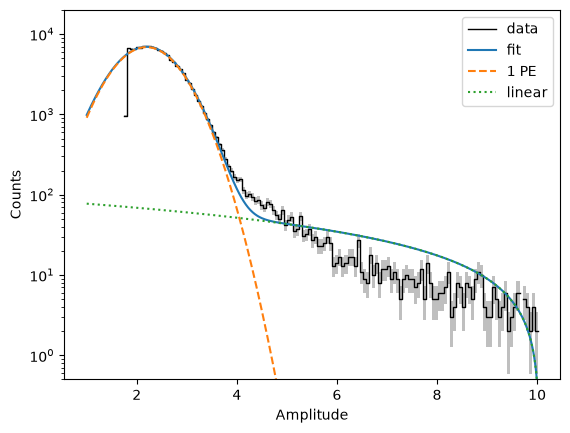

In [637]:
fit_values, fig, ax = fit_spe(
    amplitudes_spe, 
    n_gaussians=1, 
    linear=True, 
    plot=True, 
    print_fit=True,
    fit_range=(1.0, 10.0),
    bins=None,
    mu_bounds=(1.8, 4.0))

In [639]:
spe_rough = 2.20

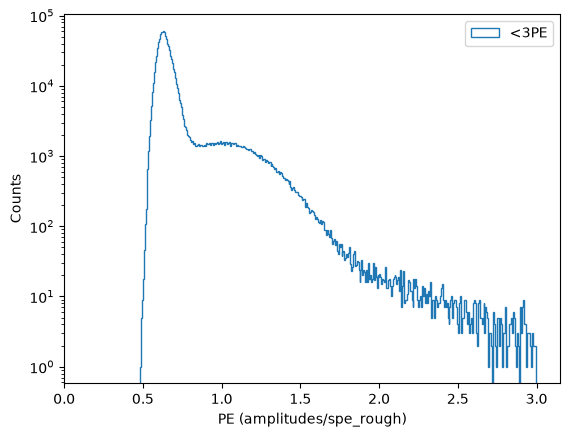

In [663]:
plt.hist(amplitudes_mv_1_2kv_low_light_10adccounts/spe_rough, bins = np.linspace(0, 3, 500), histtype='step', label = '<3PE')

#plt.axvline(10*2/2**14*1000, color='red', label = 'threshold', lw = 0.8, ls = '--')
#plt.axvline(1.8, color='green')
#plt.grid()
plt.yscale('log')
plt.xlim(0, None)
plt.legend()
plt.xlabel('PE (amplitudes/spe_rough)')
plt.ylabel('Counts')
#plt.xscale('log')
plt.show()


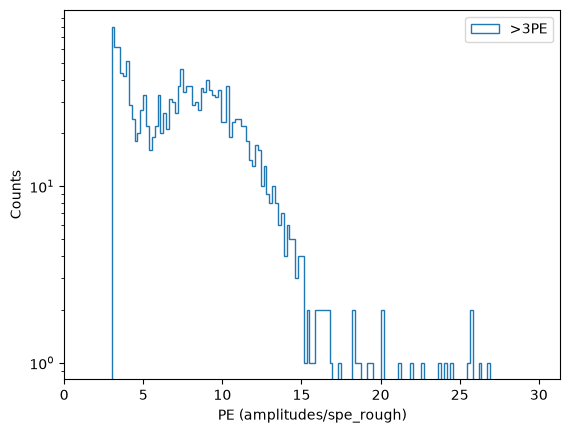

In [662]:
plt.hist(amplitudes_mv_1_2kv_low_light_10adccounts/spe_rough, bins = np.linspace(3, 30, 150), histtype='step', label = '>3PE')

#plt.axvline(10*2/2**14*1000, color='red', label = 'threshold', lw = 0.8, ls = '--')
#plt.axvline(1.8, color='green')
#plt.grid()
plt.yscale('log')
plt.xlim(0, None)
plt.legend()
plt.xlabel('PE (amplitudes/spe_rough)')
plt.ylabel('Counts')
#plt.xscale('log')
plt.show()


In [636]:
100000/31

3225.8064516129034

In [377]:
np.where(amplitudes_mv_1_2kv<3)[0]

array([    1,     3,     4, ..., 99997, 99998, 99999], shape=(84117,))

In [ ]:
#import copy
#amplitudes_mv_1_2kv_low_light_10adccounts = copy.deepcopy(amplitudes_mv)

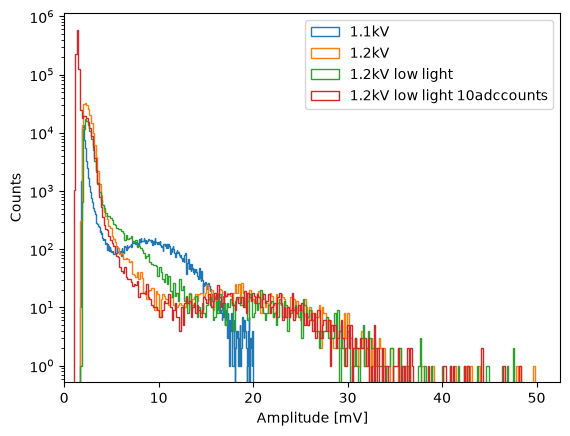

In [610]:
plt.hist(amplitudes_mv_1_1kv, bins = np.linspace(0, 20, 300, 300), histtype='step', label='1.1kV')
plt.hist(amplitudes_mv_1_2kv, bins = np.linspace(0, 50, 300, 300), histtype='step', label='1.2kV')
plt.hist(amplitudes_mv_1_2kv_low_light, bins = np.linspace(0, 50, 300), histtype='step', label='1.2kV low light')
plt.hist(amplitudes_mv_1_2kv_low_light_10adccounts, bins = np.linspace(0, 50, 300), histtype='step', label='1.2kV low light 10adccounts')

plt.yscale('log')
plt.xlim(0, None)
plt.ylabel('Counts')
plt.xlabel('Amplitude [mV]')
plt.legend()
plt.show()

In [ ]:
plt.hist(amplitudes_mv_1_2kv_low_light_10adccounts, bins = np.linspace(0, 50, 300), histtype='step', label='1.2kV low light 10adccounts')

In [612]:
10* 2 / 2**14 * 1000

1.220703125

In [446]:
5/8

0.625

In [451]:
gain = 6e5 #electr/electr

qe = 1.60217663e-19
time_width = 8 #ns

curr = 1 * gain * qe / time_width

print(curr)

1.2016324724999999e-14


In [452]:
tot_res = 44e6
volt_drop = curr * tot_res
print(volt_drop)

5.287182878999999e-07


In [690]:
print(f'{13.2e-12/(50*1.6e-19):.2e}')

1.65e+06


### Datasets

In [614]:
from dataset_catalog import load_catalog
catalog = load_catalog()

In [616]:
catalog.columns.values

<StringArray>
[                     'path',                      'name',
                   'trigger',                'voltage_kV',
                   'started',                     'ended',
                'duration_s',                    'events',
                  'baseline',              'baseline_rms',
 'baseline_within_tolerance',                 'threshold',
             'threshold_adc',                   'channel',
        'channel_thresholds',                  'polarity',
             'dynamic_range',            'target_percent',
                       'dac',              'channel_mask',
          'enabled_channels',             'record_length',
       'pre_trigger_samples',      'post_trigger_samples',
          'sample_period_ns',        'waveforms_per_file',
                   'n_files',               'stop_reason',
                  'io_level',                  'majority',
     'coincidence_window_ns',                'pair_logic',
               'board_model',             

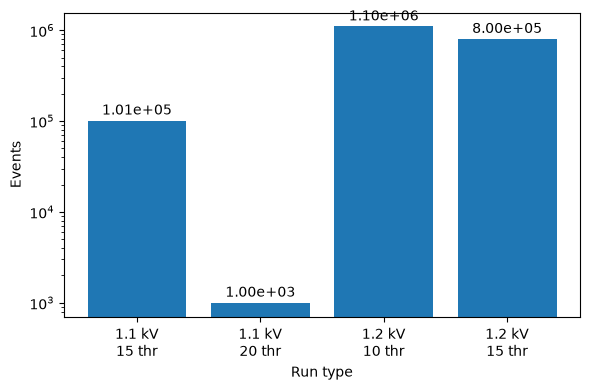

In [686]:
selected = catalog[
    (catalog["trigger"] == "coincidence")
    & (np.isclose(catalog["voltage_kV"], 1.1) | np.isclose(catalog["voltage_kV"], 1.2))
    & (catalog["events"] != 10)
]
totals = (
    selected.groupby(["voltage_kV", "threshold"], as_index=False)["events"]
    .sum()
    .sort_values(["voltage_kV", "threshold"])
)
labels = [f"{voltage:.1f} kV\n{int(threshold)} thr" for voltage, threshold in zip(totals["voltage_kV"], totals["threshold"])]

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(labels, totals["events"], )
ax.bar_label(bars, fmt="%.2e", padding=2)

ax.set_ylabel("Events")
ax.set_xlabel("Run type")
ax.set_yscale("log")
fig.tight_layout()
plt.show()

In [691]:
selected['rate'] = selected['events'] / selected['duration_s']

In [698]:
selected['name'].values

<StringArray>
[            'PMT_1_1kV_2vpp', 'PMT_1_1kV_2vpp_15adccounts',
 'PMT_1_1kV_2vpp_15adccounts', 'PMT_1_1kV_2vpp_15adccounts',
 'PMT_1_1kV_2vpp_15adccounts', 'PMT_1_2kV_2vpp_15adccounts',
 'PMT_1_2kV_2vpp_15adccounts', 'PMT_1_2kV_2vpp_15adccounts',
 'PMT_1_2kV_2vpp_10adccounts', 'PMT_1_2kV_2vpp_15adccounts',
 'PMT_1_2kV_2vpp_10adccounts']
Length: 11, dtype: str

In [699]:
selected['rate'].values

array([   43.47826087,   333.33333333,            inf,            inf,
          78.6163522 ,  2857.14285714,  1960.78431373,  1754.38596491,
        5555.55555556,  1607.7170418 , 13333.33333333])

/home/xenon/.conda/envs/pylars/lib/python3.12/site-packages/matplotlib/transforms.py:2496: RuntimeWarning: invalid value encountered in dot
  return Affine2D(np.dot(self._b.get_affine().get_matrix(),


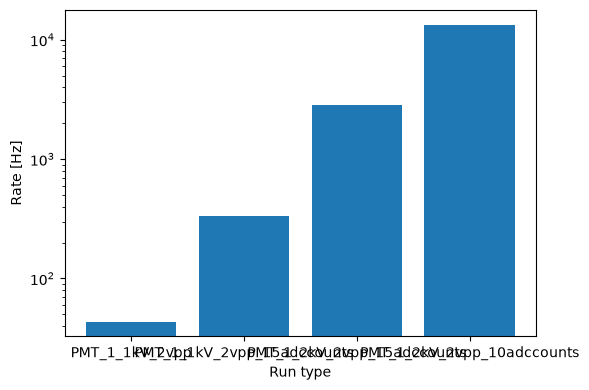

In [697]:
#plot the rate of each dataset
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(selected['name'].values, selected['rate'].values, )
ax.set_ylabel("Rate [Hz]")
ax.set_xlabel("Run type")
ax.set_yscale("log")
fig.tight_layout()

/home/xenon/.conda/envs/pylars/lib/python3.12/site-packages/matplotlib/transforms.py:2496: RuntimeWarning: invalid value encountered in dot
  return Affine2D(np.dot(self._b.get_affine().get_matrix(),
/home/xenon/.conda/envs/pylars/lib/python3.12/site-packages/matplotlib/transforms.py:2496: RuntimeWarning: invalid value encountered in dot
  return Affine2D(np.dot(self._b.get_affine().get_matrix(),


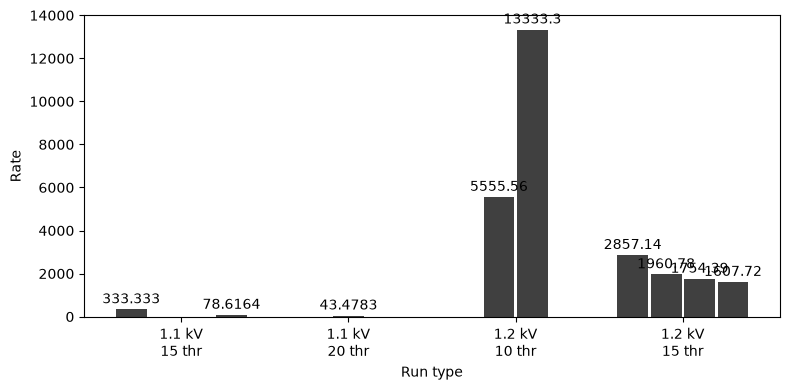

In [700]:
grouped = selected.sort_values(["voltage_kV", "threshold", "started"])
groups = list(grouped.groupby(["voltage_kV", "threshold"], sort=True))
max_n = max(len(part) for _, part in groups)
width = 0.8 / max_n

fig, ax = plt.subplots(figsize=(8, 4))
for i, ((voltage, threshold), part) in enumerate(groups):
    n = len(part)
    offsets = (np.arange(n) - (n - 1) / 2) * width
    bars = ax.bar(i + offsets, part["rate"].to_numpy(), width=width * 0.92, color="0.25")
    ax.bar_label(bars, fmt="%g", padding=2)

ax.set_xticks(np.arange(len(groups)))
ax.set_xticklabels([f"{voltage:.1f} kV\n{int(threshold)} thr" for (voltage, threshold), _ in groups])
ax.set_ylabel("Rate")
ax.set_xlabel("Run type")
fig.tight_layout()
plt.show()